In [1]:
#Cell 1: Imports, seeds, data
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import holidays
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

df = pd.read_csv("../data/processed/pjme_clean.csv", index_col="Datetime", parse_dates=True)
y = df["load_mw"].asfreq("h")
preds = pd.read_csv("../data/processed/test_predictions.csv", index_col=0, parse_dates=True)

def metrics(y_true, y_pred):
    err = y_true - y_pred
    return {"MAE": np.mean(np.abs(err)),
            "RMSE": np.sqrt(np.mean(err ** 2)),
            "MAPE_%": np.mean(np.abs(err / y_true)) * 100}

print("TensorFlow", tf.__version__, "| rows:", len(y))

TensorFlow 2.22.0-rc0 | rows: 145392


In [2]:
#Cell 2: Scale (fit on training data only)
TRAIN_END = "2016-12-31 23:00"

scaler = StandardScaler().fit(y[:TRAIN_END].values.reshape(-1, 1))
y_s = pd.Series(scaler.transform(y.values.reshape(-1, 1)).ravel(), index=y.index)

In [3]:
#Cell 3: Build windows
LOOKBACK, HORIZON = 168, 24
us_hol = holidays.US(years=range(2002, 2019))
hol_dates = pd.to_datetime(list(us_hol.keys()))

def day_features(day):
    dow = np.eye(7)[day.dayofweek]
    hol = float(day in hol_dates)
    doy = day.dayofyear
    return np.concatenate([dow, [hol,
                                 np.sin(2 * np.pi * doy / 365.25),
                                 np.cos(2 * np.pi * doy / 365.25)]])

def build(start_day, end_day):
    Xs, Xd, Y, days = [], [], [], []
    for day in pd.date_range(start_day, end_day, freq="D"):
        w_start = day - pd.Timedelta(hours=LOOKBACK)
        t_end = day + pd.Timedelta(hours=HORIZON - 1)
        if w_start < y_s.index.min() or t_end > y_s.index.max():
            continue
        Xs.append(y_s[w_start: day - pd.Timedelta(hours=1)].values)
        Y.append(y_s[day: t_end].values)
        Xd.append(day_features(day))
        days.append(day)
    return (np.array(Xs)[..., None], np.array(Xd), np.array(Y), days)

Xs_tr, Xd_tr, Y_tr, d_tr = build("2002-01-01", "2016-12-31")
Xs_va, Xd_va, Y_va, d_va = build("2017-01-01", "2017-12-31")
Xs_te, Xd_te, Y_te, d_te = build("2018-01-01", "2018-08-03")

print(Xs_tr.shape, Xs_va.shape, Xs_te.shape)
print("Test days:", d_te[0].date(), "->", d_te[-1].date())

(5471, 168, 1) (365, 168, 1) (214, 168, 1)
Test days: 2018-01-01 -> 2018-08-02


In [4]:
#Cell 4: Model
def build_model():
    seq_in = keras.Input(shape=(LOOKBACK, 1), name="history")
    day_in = keras.Input(shape=(Xd_tr.shape[1],), name="calendar")

    x = layers.LSTM(64, return_sequences=True)(seq_in)
    x = layers.Dropout(0.2)(x)
    x = layers.LSTM(32)(x)
    x = layers.Dropout(0.2)(x)
    x = layers.Concatenate()([x, day_in])
    x = layers.Dense(128, activation="relu")(x)
    out = layers.Dense(HORIZON)(x)

    m = keras.Model([seq_in, day_in], out)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mae")
    return m

model = build_model()
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ history             │ (None, 168, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 168, 64)   │     16,896 │ history[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 168, 64)   │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 32)        │     12,416 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ lstm_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ calendar            │ (None, 10)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 42)        │          0 │ dropout_1[0][0],  │
│ (Concatenate)       │                   │            │ calendar[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │      5,504 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 24)        │      3,096 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 37,912 (148.09 KB)

 Trainable params: 37,912 (148.09 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/80
86/86 - 17s - 196ms/step - loss: 0.4293 - val_loss: 0.2679 - learning_rate: 0.0010
Epoch 2/80
86/86 - 7s - 86ms/step - loss: 0.2360 - val_loss: 0.2378 - learning_rate: 0.0010
Epoch 3/80
86/86 - 7s - 82ms/step - loss: 0.2145 - val_loss: 0.2314 - learning_rate: 0.0010
Epoch 4/80
86/86 - 10s - 119ms/step - loss: 0.2024 - val_loss: 0.2286 - learning_rate: 0.0010
Epoch 5/80
86/86 - 7s - 84ms/step - loss: 0.1952 - val_loss: 0.2208 - learning_rate: 0.0010
Epoch 6/80
86/86 - 11s - 122ms/step - loss: 0.1900 - val_loss: 0.2164 - learning_rate: 0.0010
Epoch 7/80
86/86 - 10s - 116ms/step - loss: 0.1857 - val_loss: 0.2141 - learning_rate: 0.0010
Epoch 8/80
86/86 - 7s - 82ms/step - loss: 0.1851 - val_loss: 0.2122 - learning_rate: 0.0010
Epoch 9/80
86/86 - 10s - 117ms/step - loss: 0.1813 - val_loss: 0.2054 - learning_rate: 0.0010
Epoch 10/80
86/86 - 10s - 121ms/step - loss: 0.1806 - val_loss: 0.2077 - learning_rate: 0.0010
Epoch 11/80
86/86 - 7s - 78ms/step - loss: 0.1777 - val_loss: 0.204

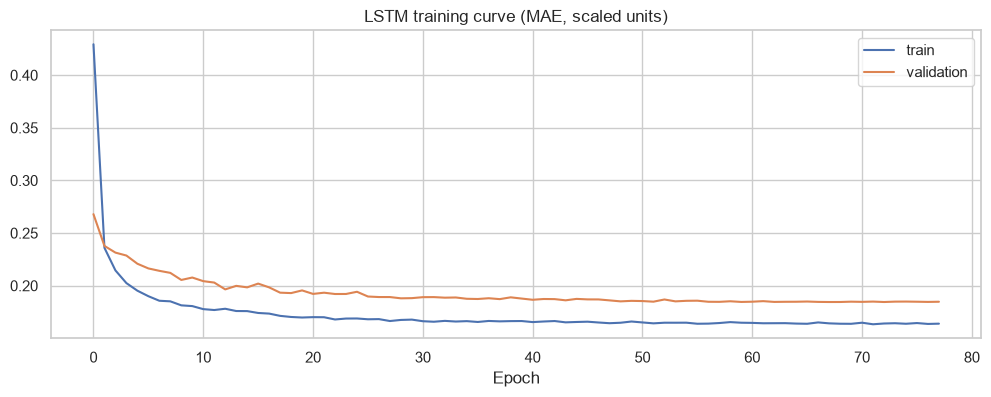

In [5]:
#Cell 5: Train
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5),
]

history = model.fit(
    [Xs_tr, Xd_tr], Y_tr,
    validation_data=([Xs_va, Xd_va], Y_va),
    epochs=80, batch_size=64, shuffle=True,
    callbacks=callbacks, verbose=2,
)

plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("LSTM training curve (MAE, scaled units)")
plt.xlabel("Epoch"); plt.legend()
plt.savefig("../reports/figures/07_lstm_training.png", dpi=150)
plt.show()

In [7]:
#Cell 6: Predict on the test set and compare
pred_s = model.predict([Xs_te, Xd_te], verbose=0)
pred_mw = scaler.inverse_transform(pred_s.reshape(-1, 1)).reshape(-1, HORIZON)

idx = pd.DatetimeIndex([d + pd.Timedelta(hours=h) for d in d_te for h in range(HORIZON)])
lstm_pred = pd.Series(pred_mw.ravel(), index=idx, name="lstm")

common = preds.loc[lstm_pred.index].copy()
common["lstm"] = lstm_pred

results = {m: metrics(common["actual"], common[m])
           for m in ["naive_24", "naive_168", "lightgbm", "lstm"]}
print(pd.DataFrame(results).T.round(2))

               MAE     RMSE  MAPE_%
naive_24   2530.64  3397.36    7.91
naive_168  3622.15  4948.33   11.11
lightgbm   2016.42  2700.44    6.24
lstm       1514.63  2144.81    4.59


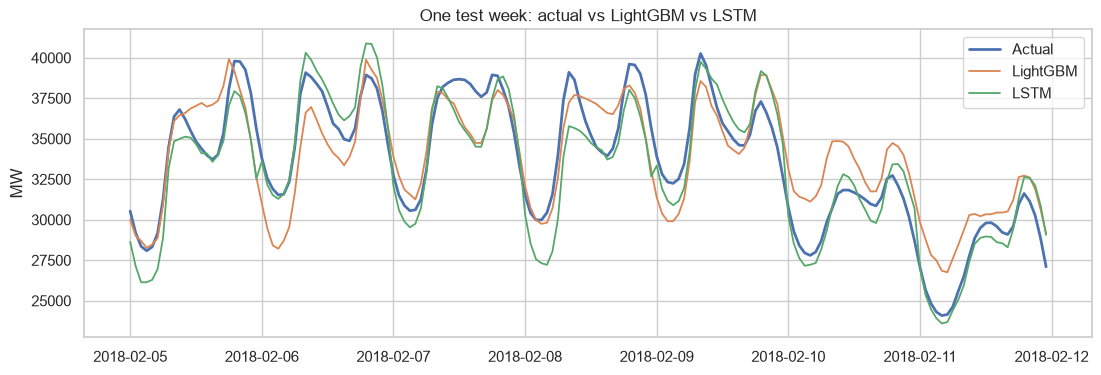

              0       1       2       3       4       5       6       7       8       9       10      11      12      13      14      15      16      17      18      19      20      21      22      23
lightgbm  1870.0  1810.0  1743.0  1705.0  1678.0  1672.0  1766.0  1824.0  1780.0  1637.0  1584.0  1690.0  1845.0  2089.0  2265.0  2410.0  2494.0  2592.0  2615.0  2526.0  2409.0  2249.0  2139.0  2002.0
lstm       412.0   653.0   745.0   828.0   867.0   956.0   982.0   903.0   902.0   940.0  1152.0  1491.0  1767.0  1916.0  2054.0  2109.0  2203.0  2275.0  2361.0  2423.0  2302.0  2139.0  2046.0  1925.0


In [8]:
#Cell 7: Plot and error by hour
week = common["2018-02-05":"2018-02-11"]
plt.figure(figsize=(13, 4))
plt.plot(week["actual"], label="Actual", lw=2)
plt.plot(week["lightgbm"], label="LightGBM", lw=1.3)
plt.plot(week["lstm"], label="LSTM", lw=1.3)
plt.title("One test week: actual vs LightGBM vs LSTM")
plt.ylabel("MW"); plt.legend()
plt.savefig("../reports/figures/08_lstm_vs_lightgbm.png", dpi=150)
plt.show()

err = pd.DataFrame({
    "lightgbm": (common["actual"] - common["lightgbm"]).abs(),
    "lstm": (common["actual"] - common["lstm"]).abs(),
})
print(err.groupby(err.index.hour).mean().round(0).T.to_string())

In [9]:
#Cell 8: Save
lstm_pred.to_csv("../data/processed/lstm_predictions.csv")
model.save("../models/lstm.keras")